# Zadanie 2A — BloodMNIST

**Cel:** przygotuj dane obrazowe, wytrenuj i oceń model klasyfikujący osiem typów komórek krwi, a następnie zastosuj samodzielnie wybraną metodę wyjaśniania predykcji.

### Importing needed functions and libraries

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from torch import optim

from huggingface_hub import hf_hub_download
from sklearn.metrics import classification_report, confusion_matrix, f1_score, balanced_accuracy_score,precision_score, recall_score
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
import torch.nn.functional as F
from sklearn.utils.class_weight import compute_class_weight
import random
from sklearn import metrics
from captum.attr import LayerGradCam

In [2]:
DATA_DIR = Path("data/zadanie-2a")
DATA_DIR.mkdir(parents=True, exist_ok=True)

data_path = hf_hub_download(
    repo_id="AI-MED-AGH/Recruitment-Task-2A",
    filename="original/bloodmnist.npz",
    repo_type="dataset",
    local_dir=DATA_DIR,
)
data = np.load(data_path)
print(data.files)

['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']


## A — Poznanie i przygotowanie danych

Sprawdź strukturę obrazów, kanały, klasy, liczebności i jakość danych. Zachowaj oficjalne podziały treningowy, walidacyjny i testowy. Wykonaj preprocessing i augmentację; wszystkie decyzje zależne od danych podejmuj wyłącznie na zbiorze treningowym.

### Setting random seed 

Setting a random seed ensures strict reproducibility by forcing pseudorandom number generators to output the exact same sequence of values during every execution. This guarantees identical network weight initialization, dataset shuffling, and dropout application, which is mandatory for reliable debugging and mathematical comparison of different model architectures.

In [3]:
random.seed(42) # Freezes the built-in Python generator
np.random.seed(42) # Ensures determinism for mathematical operations on matrices and random transformations within the NumPy
torch.manual_seed(42) # Fixes the random seed for all tensor operations performed on the CPU
torch.cuda.manual_seed_all(42) # Enforces reproducibility on NVIDIA graphics accelerators (CUDA)
torch.mps.manual_seed(42) # Sets a hardware seed dedicated specifically to the graphics accelerator in the Apple architecture
torch.backends.cudnn.deterministic = True # Prevents silent mathematical approximations
torch.backends.cudnn.benchmark = False # Disables hardware autotuning

### Initializing device 

Since we want full computional power, first we need to define the device used to make all calculations included in training process

In [4]:
device = torch.device("mps") if torch.backends.mps.is_available() else torch.device("cpu")

MPS ( Metal Performance Shaders ) - Functions that increase computional power on Apple's GPUs
.Apple Silicon chips feature a unified memory architecture, which allows the GPU to rapidly process large AI models directly within the same RAM accessible to the CPU.

## Loading the bloodMNIST dataset

In [5]:
data = np.load("data/zadanie-2a/original/bloodmnist.npz")
list(data.keys())

['train_images',
 'train_labels',
 'val_images',
 'val_labels',
 'test_images',
 'test_labels']

This means that under these specific keys there are physical arrays containing cell images and their corresponding labels, already divided into usable subsets.

According to *https://medmnist.com/* BloodMNIST dataset has 17,092 samples :
* Training set - 11,959
* Validation set - 1,712
* Test set - 3,421

#### Checking if there are any missing records in our dataset

In [6]:
data_train = data["train_images"]
y_train = data["train_labels"]
print("Shape of Training set : ",data_train.shape)

data_val = data["val_images"]
y_val = data["val_labels"]
print("Shape of Validation set : ", data_val.shape)

data_test = data["test_images"]
y_test = data["test_labels"]
print("Shape of Test set : ", data_test.shape)

Shape of Training set :  (11959, 28, 28, 3)
Shape of Validation set :  (1712, 28, 28, 3)
Shape of Test set :  (3421, 28, 28, 3)


There are no missing records, however let's check if there are any missing values

#### Checking for missing values

In [7]:
print(np.isnan(data_train).any())
print(np.isnan(data_val).any())
print(np.isnan(data_test).any())

False
False
False


There are no *NaN* values in dataset 

#### Exploring the structure of every image in dataset 

In [7]:
# Range of colors in training set 
print("Min val in Training set : ", data_train.min())
print("Max val in Training set : ", data_train.max())

# Range of colors in validation set 
print("Min val in Validation set : ", data_val.min())
print("Max val in Validation set : ", data_val.max())

# Range of colors in test set 
print("Min val in Test set : ", data_test.min())
print("Max val in Test set : ", data_test.max())


Min val in Training set :  0
Max val in Training set :  255
Min val in Validation set :  0
Max val in Validation set :  255
Min val in Test set :  0
Max val in Test set :  255


Now we are familiar with image structure in BloodMNIST dataset. Every image can be represented as a 3 dimensional array with 28 * 28 * 3 numbers (as was checked by *shape* attribute). Every number is in range 0-255 (made sure above) which represents color of singular pixel (0-black, 255-white) in the image matrix.

### Every class in dataset and its count 

#### Classes

In [8]:
# Training set 
print("Training set : ")
print(f"All classes: {np.unique(y_train)}, length : {len(np.unique(y_train))} ")

# Validation set 
print("Validation set : ")
print(f"All classes: {np.unique(y_val)}, length : {len(np.unique(y_val))} ")

# Test set
print("Test set : ")
print(f"All classes: {np.unique(y_test)}, length : {len(np.unique(y_test))} ")


Training set : 
All classes: [0 1 2 3 4 5 6 7], length : 8 
Validation set : 
All classes: [0 1 2 3 4 5 6 7], length : 8 
Test set : 
All classes: [0 1 2 3 4 5 6 7], length : 8 


Numbers 0-7 represent each of the blood cell type. All 3 datasets (training,validation,test) have 8 classes, meaning that no class is missing.

#### Count 

In [9]:
# Counting amount of samples in each class 
train_count = np.unique(y_train, return_counts = True, sorted = True)
val_count = np.unique(y_val, return_counts = True, sorted = True)
test_count = np.unique(y_test, return_counts = True, sorted = True)

data_dict = {
    "Class" : train_count[0],
    "Count_train" : train_count[1],
    "Count_validation" : val_count[1],
    "Count_test" : test_count[1],
}

pd.DataFrame(data_dict).set_index("Class")

,Count_train,Count_validation,Count_test
Class,,,
0,852,122,244
1,2181,312,624
2,1085,155,311
3,2026,290,579
4,849,122,243
5,993,143,284
6,2330,333,666
7,1643,235,470


The dataset is imbalanced. Class 6 has 2,330 training samples, while the least represented classes, 0 and 4, have 852 and 849 samples. The data split is stratified; class proportions remain consistent across subsets, and the test set is exactly twice the size of the validation set for each class. It means that we have to calculate weights accordingly to number of samples in each class using simple math formula : 

**Weight = Total Number of Samples / Number of Classes x Number of Samples in that Class**

In [10]:
# Calculating the weights
computed_weights_help = compute_class_weight(
    class_weight = 'balanced', 
    classes = np.unique(y_train), 
    y = y_train.ravel()
)

# The `weight` parameter of `CrossEntropyLoss` accepts only a PyTorch tensor in 32-bit format
# 'computed_weight' is a type float64 so casting and changing type from numpy array to tensor is neccessary

# Changing type 
weights_torch= torch.tensor(computed_weights_help)

# Casting 
computed_weights = weights_torch.float().to(device)

PyTorch requires all tensors involved in a mathematical operation to physically be on the same hardware device to prevent cross-device communication bottlenecks. Transferring the weights tensor from the CPU's RAM to the hardware accelerator ensures that the *CrossEntropyLoss* function can execute efficiently without triggering a runtime device mismatch error during the forward pass.

### Example images of a blood cell found in dataset 

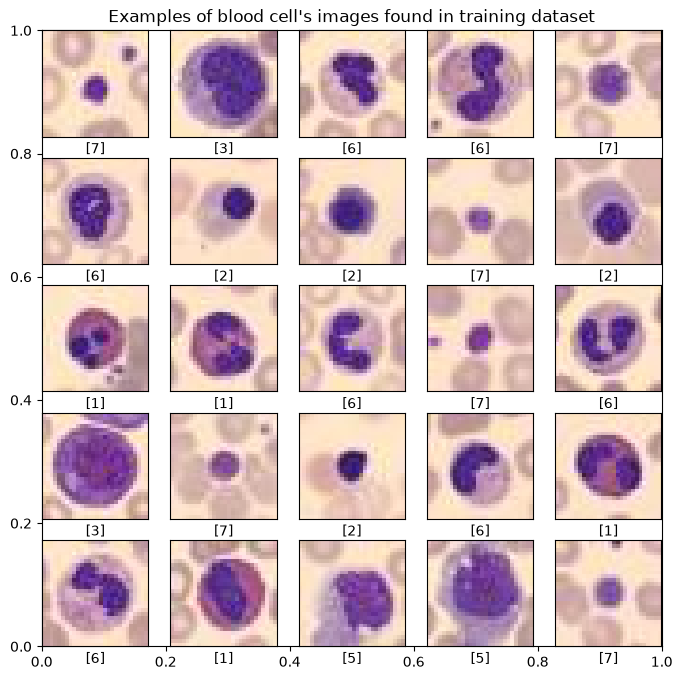

In [11]:
plt.figure(figsize=(8, 8))
plt.title("Examples of blood cell's images found in training dataset")
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(data_train[i])
    plt.xlabel(y_train[i])
plt.show()

### Data Augmentation

It's a technique that artificially expands training dataset by creating modified versions of existing data without changing their original labels. In this case it helps the model to actually learn the structure and form of a blood cell rather than memorizing pixel positions. 

In [12]:
transform_train = transforms.Compose([
    transforms.ToPILImage(), # Converts input array to Python Imaging LIbrary Object
    transforms.RandomHorizontalFlip(p=0.5), # Flips horizontally with prob.50%
    transforms.RandomRotation(degrees=15), # Rotates image by degrees ranging from [-15,15]
    transforms.ToTensor()
])

Note : `transforms.ToTensor()` automatically scales pixel values ranging from 0-255 to 0-1 which is essential for input value in CNN network and computational performance.

Deep learning frameworks, such as PyTorch, operate on their own data structures known as tensors which must be provided in organized batches. A classification model lacks built-in mechanisms for reading raw NumPy arrays, managing RAM, or applying transformations on the fly.

In [13]:
class BloodMNISTDataset(Dataset):
    def __init__(self, images, labels, transform = None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        image_sample = self.images[index]
        label_sample = self.labels[index]
        if self.transform is not None:
            image_sample = self.transform(image_sample)
        return image_sample,label_sample.flatten()

training_init = BloodMNISTDataset(data_train,y_train,transform_train) # augmentation realization 

Because validation dataset and test dataset are purely for evaluating models efficiency. Applying random deformations (augmentations) to them would completely distort the evaluation results and make it impossible to evaluate the algorithm's effectiveness on real data. 
That's why it's vital to create a second pipeline just for evaluating the model.


In [14]:
transform_ValAndTest = transforms.Compose([
    transforms.ToPILImage(), 
    transforms.ToTensor(), 
])

validation_init = BloodMNISTDataset(data_val, y_val, transform_ValAndTest)
test_init = BloodMNISTDataset(data_test, y_test, transform_ValAndTest)

### Initializing DataLoader for efficiently loading and processing data

*DataLoader* is an essential tool for processing and loading data during training. Without it the system would have to load all necessary data (couple GB or even more) at once to RAM or VRAM which would quickly cause the system to freeze.

In [20]:
# Connecting image matrix and labels so it can be an argument to DataLoader function

dataloader_train = DataLoader(training_init, batch_size=32, shuffle=True)
dataloader_val = DataLoader(validation_init, batch_size=32, shuffle=False)
dataloader_test = DataLoader(test_init, batch_size=32, shuffle=False)

## B — Modelowanie i walidacja

Wytrenuj model wieloklasowy. Przeanalizuj architekturę, funkcję kosztu, optymalizator i sposób użycia walidacji do wyboru modelu lub zatrzymania treningu. Zbiór testowy pozostaw nietknięty do końcowej oceny.

## Choosing and implementing the model 
To complete this classification assignment *Convolutional Neural Network* is going to be used as our multi-class model.
A CNN is a type of deep learning model primarily used for processing structured grid data like images. Unlike traditional feedforward neural networks, CNNs leverage the spatial structure of the input by using convolutional layers that apply filters to capture patterns like edges, textures, and shapes, which is exactly what we want.

### Defining a CNN class

This is necessary because the algorithm must know which data to operate on and which functions to use.
A class must be defined; otherwise, the algorithm would not be able to correctly adjust the weights.
The class consists of two stages: the stage of creating the convolutional network and the stage of information flow through that network.

* *Convolutional layer*  is a feature that slides small filter matrices across input data to detect local patterns and create feature maps
* *Pooling layer* is a downsampling operation that reduces the spatial dimensions (width and height) of feature maps while retaining the most important information (reduces the chances of overfitting)
* *Fully connected layer* is a neural network layer where every neuron is connected to every single neuron in the previous layer

In [21]:
class CNN(nn.Module):

    # Creating the CNN 
    def __init__(self, in_channels, num_classes):
        super(CNN, self).__init__()

        # First convolutional layer
        self.conv_lay1 = nn.Conv2d( in_channels = in_channels, out_channels = 8, kernel_size = 3, padding = 1)
        # Max pooling layer 
        self.pool = nn.MaxPool2d( kernel_size = 2, stride = 2)
        # Second convolutional layer
        self.conv_lay2 = nn.Conv2d( in_channels = 8, out_channels = 16, kernel_size = 3, padding = 1)
        self.pool= nn.MaxPool2d( kernel_size = 2, stride = 2)
        # Fully connected layer
        self.fcl = nn.Linear(16 * 7 * 7, num_classes)

    # Flow of the tensors between layers
    def forward(self, x):
        x = F.relu(self.conv_lay1(x))
        x = self.pool(x)
        x = F.relu(self.conv_lay2(x))
        x = self.pool(x)
        x = x.reshape(x.shape[0], -1)
        x = self.fcl(x)
        return x 
        

### Creating model 

In [22]:
# Creating the model
model = CNN(in_channels = 3, num_classes = 8).to(device)

### Training CNN model
Since this a a multi class classification problem, to measure performance of the model *cross-entropy loss function* will be used. To optimize CNN we will use *Adam optimizer*.

* *Training loss* is calculated on training dataset, used to update the weights. The more training on the model the smaller training loss should be. 
* *Validation loss* is calculated on validation dataset. If *Training loss* still decreases but the *Validation loss* is increasing it means that the model is starting to overfit and that's the moment when learning must be stopped.

To prevent overfitting it's important to keep track of those two values. The training process should be interrupted by a conditional statement if the validation error has not improved over a specified number of consecutive epochs (in the code below it's 5).

In [23]:
# Defining the loss function
criterion = nn.CrossEntropyLoss(weight = computed_weights) # Now it's time to use weights we calculated before
# Defining the optimizer
optimizer = optim.Adam(model.parameters(), lr = 0.001)
# Defining epoch number 
epochs = 50 
# Defining trainig loss 
init_loss = np.inf #(inf to ensure that after first iteration training loss is lower than initialized one) 
# Defining paremeter to know if the model is starting to overfit
patience = 5 
curr_patience = 0
mean_val_loss = []


for epoch in range(epochs):
    # Training process
    model.train()
    for batch_train, target_train in dataloader_train:
        # changing location of batches from RAM to MPS
        batch_train = batch_train.to(device) 
        target_train = target_train.to(device)
        # clearing the gradient (without this step the algorithm would wrongly improve weights)
        optimizer.zero_grad()
        # Forward passing the data 
        logits_train = model(batch_train)
        # Applying loss function
        loss_train = criterion(logits_train,torch.squeeze(target_train)) # 'squeeze' reduces dimension of a target_train tensor
        # Backpropagation
        loss_train.backward()
        # Updating parameters
        optimizer.step()

    # Validation process
    model.eval()
    with torch.no_grad():
        # Defining validation loss 
        val_loss = 0
        for batch_val, target_val in dataloader_val:
            batch_val = batch_val.to(device)
            target_val = target_val.to(device)
            logits_val = model(batch_val)
            loss_val= criterion(logits_val, torch.squeeze(target_val))
            val_loss += loss_val
            
        mean_val_loss.append(val_loss / len(dataloader_val))
        
        # Checking if model is still learning or is it starting to get overfitted 
        if mean_val_loss[epoch] < init_loss:
            init_loss = mean_val_loss[epoch]
            curr_patience = 0
            torch.save(model.state_dict(), 'CNN_best_parameters/model_weights.pth') # Saving the best weight values before overfitting
        else: 
            curr_patience += 1
            if curr_patience > patience:
                break


## C — Ocena i wyjaśnialność

Oceń wybrany model na oficjalnym zbiorze testowym, używając odpowiednich metryk wieloklasowych i analizy pomyłek. Znajdź w literaturze lub wiarygodnym źródle metodę wizualnego wyjaśniania modeli obrazowych, zastosuj ją do poprawnych i błędnych predykcji z kilku klas oraz omów jej ograniczenia. Podaj źródło.

## Evaluating the Model 

Now that we have a file with the best parameters (weights and biases) we can proceed to evaluate the model on test dataset

### Initializing evaluation model

In [24]:
eval_model = CNN(in_channels=3, num_classes=8).to(device) 
# Loading parameters to eval_model
eval_model.load_state_dict(torch.load("CNN_best_parameters/model_parameters.pth"))
eval_model.eval()
print(eval_model)

CNN(
  (conv_lay1): Conv2d(3, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv_lay2): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fcl): Linear(in_features=784, out_features=8, bias=True)
)


Everything looks good, now we can move to calculating metrics that will help us actually evalute the CNN model

### Calculating Metrics

In [25]:
y_pred_help = []
y_target_help = []

with torch.no_grad():
    for batch_test, target_test in dataloader_test:
        batch_test = batch_test.to(device)
        target_test = target_test.to(device)
        logits_test = eval_model(batch_test)
        prediction = torch.argmax(logits_test, dim = 1)
        y_pred_help.append(prediction)
        y_target_help.append(target_test.squeeze())

y_pred = torch.cat(y_pred_help, dim=0)
y_target = torch.cat(y_target_help, dim=0)

# Since we want to use built-in functions from scikit-learn to calculate metrcis we have to include the fact that
# it operates exclusively on the CPU and understands only NumPy data structures

y_pred = y_pred.cpu()
y_pred_array = y_pred.numpy()

y_target = y_target.cpu()
y_target_array = y_target.numpy()


Now we have two lists ready to be used for calculating metrcis. The metrics we want to calculate are : 

* *Balanced Accuracy* - It represents the mathematical ratio of all correctly classified images to the total number of samples in the dataset. It indicates the overall, global performance of a model. In medical analysis systems (such as BloodMNIST), however, it can be misleading because one type of blood cell is significantly rarer in the dataset than others (class imbalance), a model might achieve high accuracy simply by ignoring the minority class, that's why we use *Balanced Accuracy* to avoid getting false value of high accuracy on our model.

* *Macro F1-Score* - It tells us how well the model performs on each class individually, treating them all as equally important.

* *Precision* - It measures the reliability of a model during classification. It focuses on minimizing false positive errors.

* *Recall* - It measures its effectiveness in detection. It focuses on minimizing false negative errors which are situations where model didn't correctly made classification.

In [26]:
# Balanced Accuracy : 
balanced_accuracy = balanced_accuracy_score(y_target_array,y_pred_array)
print(f"Balanced accuracy : {balanced_accuracy:.4f}")

# Macro F1-Score 
macro_f1 = f1_score(y_target_array,y_pred_array, average = "macro")
print(f"Macro F1-Score : {macro_f1:.4f}")

# Precision 
precision = precision_score(y_target_array,y_pred_array, average = "macro")
print(f"Precision Score : {precision:.4f}")

# Recall
recall = recall_score(y_target_array,y_pred_array, average = "macro")
print(f"Recall Score : {recall:.4f}")

Balanced accuracy : 0.9033
Macro F1-Score : 0.9056
Precision Score : 0.9090
Recall Score : 0.9033


The CNN model demonstrates strong and consistent performance, exceeding 0.90 across all evaluated metrics. The minimal difference between Precision Score (0.9090) and Recall Score (0.9033) indicates a well calibrated network that maintains a steady balance between false positive and false negative errors. High Balanced accuracy (0.9033) and Macro F1-Score (0.9056) confirm that the model effectively handles dataset imbalance, generalizing successfully across all classes without overfitting to the majority groups.

### Confusion Matrix 

Confusion Matrix is a great tool to visualize were our model made mistakes and which pair of blood cells where most commonly misclassified

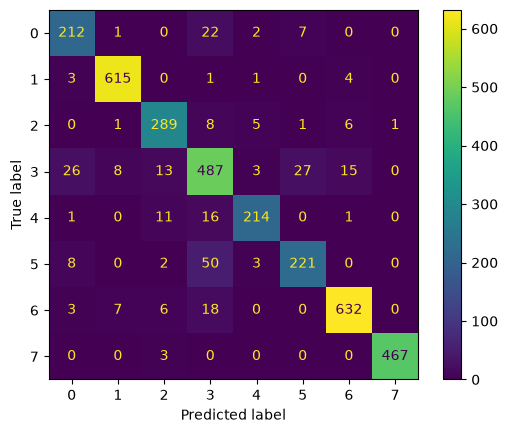

In [27]:
confusion_matrix = metrics.confusion_matrix(y_target_array, y_pred_array)
cm_display = metrics.ConfusionMatrixDisplay(confusion_matrix = confusion_matrix)
cm_display.plot()
plt.show()

### Conclusions 

* The very small gap between precision (0.9090) and recall (0.9033) clearly demonstrates that the class weights implemented in the loss function have functioned effectively. The model learns in a balanced manner and does not artificially inflate its statistics by favoring more frequent blood cell types.
* For classes 1,6,7 the model makes almost no mistakes. In the case of class 7, the algorithm made only 3 errors out of 470 physical images, and in class 1 it made only 9 errors out of 624 samples. This proves that their morphological features (shape, size, color) are very unique and easy to capture by convolutional filters.
* The column corresponding to the prediction of class 3 accumulates the highest number of errors from other classes. Our algorithm shows a clear tendency to classify class 3 when faced with a difficult image. It incorrectly assigned the label 3 to 50 images from class 5, 22 images from class 0, 18 from class 6, and 16 from class 4. This leads to a drastic drop in precision for class 3.
* A cell from class 5 was misclassified as class 3 on 50 occasions, while the reverse occurred 27 times (a genuine class 3 cell misclassified as class 5). A similar pattern is observed between classes 0 and 3 (22 misclassifications in one direction and 26 in the other). This indicates that these blood cells are visually very similar, and a simple CNN is unable to detect the high frequency details that would distinguish them.

As shown in the confusion matrix analysis, while our CNN model performs exceptionally well on distinct blood cell types like classes 1, 6, and 7, it faces a significant bottleneck when distinguishing between morphologically similar classes 0, 3, and 5. Class 3 in particular acts as a strong attractor for misclassifications. To investigate the root cause of this issue and verify whether the network bases its decisions on actual biological features rather than background artifacts (shortcut learning), we must look inside the "black box". In the following section, we will apply Grad-CAM (Gradient-weighted Class Activation Mapping) to visually explain the model's reasoning on both correct and incorrect predictions from this problematic cluster.

# Grad-CAM

*Grad-CAM (Gradient-weighted Class Activation Mapping)* - Is sa technique used to improve the interpretability of deep neural networks, particularly CNNs.It helps visualize which regions of an image contribiute the most to the model's predictions by producing a heatmap overlay on the original input image.

In [28]:
# Extracting images 

true_positives = []
false_positives = []
count_fp = 0
count_tp = 0


with torch.no_grad():
    for images, labels in dataloader_test:
        images = images.to(device)
        labels = labels.to(device)
        logits = eval_model(images) # Calculating predictions for one whole batch (32 images)
        preds = torch.argmax(logits, dim=1)
        
        for i in range(len(preds)):
            # Looking for False Positives
            if preds[i] == 3 and labels[i] == 5:
                single_image = images[i].unsqueeze(0) 
                false_positives.append(single_image)
                count_fp += 1 
                if count_fp == 2:
                    break
            # Looking for True Positives
            if preds[i] == 5 and labels[i] == 5:
                single_image = images[i].unsqueeze(0)
                true_positives.append(single_image)
                count_tp += 1
                if count_tp == 2:
                    break

In [30]:
# Implementing Grad-CAM for True Positives

cam_tp = LayerGradCam( forward_func = eval_model, layer = eval_model.conv_lay2)
attribution_map_tp = cam_tp.attribute(true_positives[0], target = 5)
rescaled_image_tp = F.interpolate(attribution_map_tp, size = (28,28), mode='bilinear')

# Converting image format from PyTorch to NumPy
img_tp = true_positives[0].cpu().numpy().squeeze()
img_tp = np.transpose(img_tp, (1,2,0)) # Height, Width, Channels

rescaled_image_tp = rescaled_image_tp.detach()
img_heat_tp = rescaled_image_tp.cpu().numpy().squeeze()

In [32]:
# Implementing Grad-CAM for False Positives

cam_fp = LayerGradCam( forward_func = eval_model, layer = eval_model.conv_lay2)
attribution_map_fp = cam_fp.attribute(false_positives[0], target = 3)
rescaled_image_fp = F.interpolate(attribution_map_fp, size = (28,28), mode='bilinear')

# Converting image format from PyTorch to NumPy
img_fp = false_positives[0].cpu().numpy().squeeze()
img_fp = np.transpose(img_fp, (1,2,0)) # Height, Width, Channels

rescaled_image_fp = rescaled_image_fp.detach()
img_heat_fp = rescaled_image_fp.cpu().numpy().squeeze()

### Visualisation 

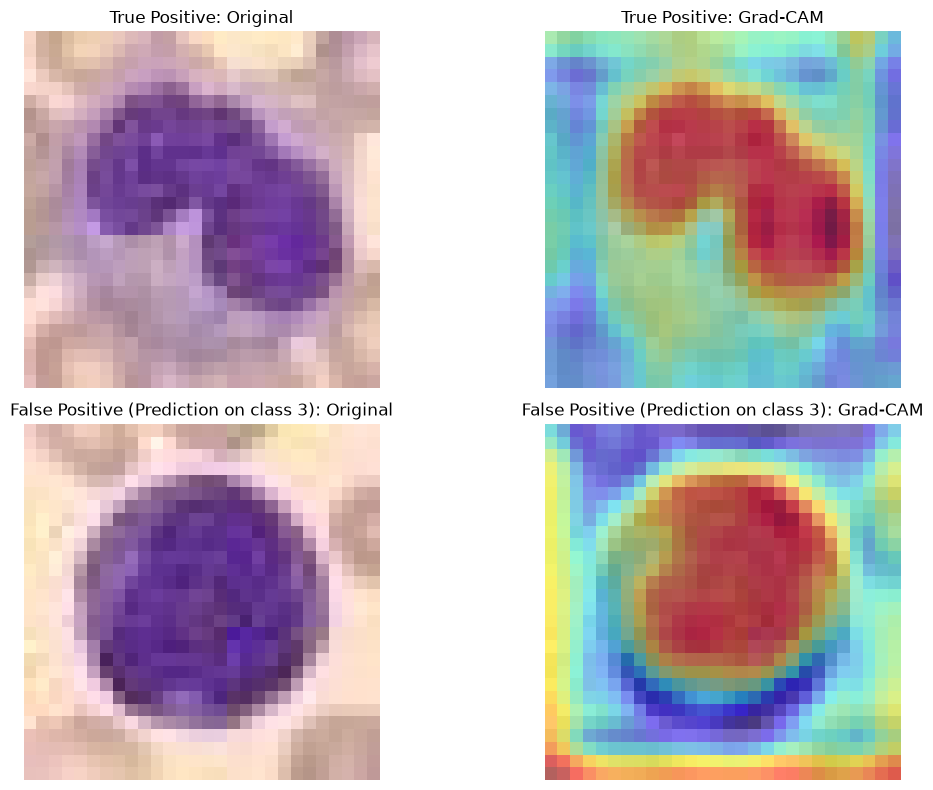

In [33]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# True Positives
axes[0, 0].imshow(img_tp)
axes[0, 0].set_title("True Positive: Original")
axes[0, 0].axis('off')

axes[0, 1].imshow(img_tp)
axes[0, 1].imshow(img_heat_tp, cmap='jet', alpha=0.5)
axes[0, 1].set_title("True Positive: Grad-CAM")
axes[0, 1].axis('off')

# False Positives
axes[1, 0].imshow(img_fp)
axes[1, 0].set_title("False Positive (Prediction on class 3): Original")
axes[1, 0].axis('off')

axes[1, 1].imshow(img_fp)
axes[1, 1].imshow(img_heat_fp, cmap='jet', alpha=0.5)
axes[1, 1].set_title("False Positive (Prediction on class 3): Grad-CAM")
axes[1, 1].axis('off')

plt.tight_layout()
plt.show()

### Conclusions

As shown in the visualizations above, when the model correctly predicts class 5, the primary criterion for its decision is the blood cell itself, with the highest activations localized on the structure. Whereas, in the false positive scenario (incorrect prediction of class 3) the activation map diffuses beyond the cell boundaries. This indicates that the network's spatial attention includes background noise into its decision making process. It should be noted that the general overflow of the heatmap in both cases is also a known limitation of the Grad-CAM method, resulting from the bilinear upsampling of low-resolution feature maps from the final convolutional layer.

## Oddanie zadania

Zapisz kod, wyniki, wykresy i uzasadnienia w tym notatniku. Podaj użyte źródła oraz narzędzia AI i zadbaj o odtwarzalność rozwiązania. Umieść rozwiązania w swoim repozytorium.